# 02 — Unsupervised Learning: Clustering & Dimensionality Reduction

## Objective
This notebook implements and evaluates **Section 3 (Clustering Task)** of the project specification across the 10 U.S. cities:
1. **Feature Normalization:** Within-city demand Z-score (`demand_city_zscore`) combined with standardized meteorological and cyclical temporal features (`temperature`, `humidity`, `wind_speed`, `pressure`, `hour_sin/cos`, `month_sin/cos`) so clusters represent **universal consumption–weather operating regimes** rather than city population size.
2. **K-Means Clustering (`k = 2..8`):** Optimal $k$ selection using the **Elbow Method (Inertia)**, **Silhouette Score**, and **Bootstrap Cluster Stability (Adjusted Rand Index / ARI)**.
3. **Dimensionality Reduction (`PCA` & `t-SNE`):** Visualizing the 9-dimensional feature space in 2D colored by cluster regime and by season.
4. **DBSCAN & Hierarchical Clustering:** Isolating low-density extreme weather–demand noise via **DBSCAN** ($k$-distance graph) and visualizing hierarchical cluster merges via **Ward's Linkage Dendrogram**.
5. **Domain Interpretation:** Characterizing each cluster's physical weather and load signature.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (14, 5.5)
plt.rcParams["font.size"] = 11

processed_dir = PROJECT_ROOT / "data/processed"
sample_df = pd.read_parquet(processed_dir / "clustered_sample_data.parquet")
eval_df = pd.read_csv(processed_dir / "kmeans_evaluation.csv")
profile_df = pd.read_csv(processed_dir / "cluster_profiles.csv")
Z_linkage = np.load(processed_dir / "ward_linkage.npy")
k_distances = np.load(processed_dir / "dbscan_k_distances.npy")

with open(processed_dir / "clustering_metadata.json", "r", encoding="utf-8") as fp:
    meta = json.load(fp)

print("Clustering Metadata Summary:")
print(json.dumps(meta, indent=2))
display(eval_df)

Clustering Metadata Summary:
{
  "best_k": 4,
  "pca_explained_variance_ratio": [
    0.2767,
    0.1656,
    0.1274
  ],
  "pca_total_2d_variance_pct": 44.24,
  "pca_total_3d_variance_pct": 56.97,
  "kmeans_best_silhouette": 0.1528,
  "kmeans_best_stability_ari": 0.9671,
  "hierarchical_silhouette": 0.1035,
  "dbscan_metrics": {
    "eps": 1.35,
    "min_samples": 25,
    "n_clusters": 1,
    "n_noise": 1302,
    "noise_ratio_pct": 13.02,
    "silhouette_non_noise": NaN
  }
}


,k,inertia,silhouette_score,stability_ari_mean,stability_ari_std,composite_score
0,2,73480.396590,0.174193,0.993983,0.001977,0.461120
1,3,64870.542614,0.158107,0.944766,0.045268,0.433437
2,4,59128.347477,0.152805,0.967060,0.015928,0.437794
3,5,55005.661944,0.149524,0.918217,0.011313,0.418566
4,6,51586.425011,0.154700,0.930391,0.019975,0.426192
5,7,49066.396036,0.157875,0.880345,0.109576,0.410740
6,8,46894.189826,0.158115,0.706113,0.118965,0.349914


## 1. K-Means Evaluation: Elbow Method, Silhouette Score & Cluster Stability
Below we plot the three evaluation criteria across $k \in \{2, 3, 4, 5, 6, 7, 8\}$:
1. **Within-Cluster Sum of Squares (Inertia)** for the Elbow Method.
2. **Silhouette Score** measuring cluster cohesion vs. separation.
3. **Bootstrap Cluster Stability (Adjusted Rand Index — ARI)** across 5 random 80% subsamples.

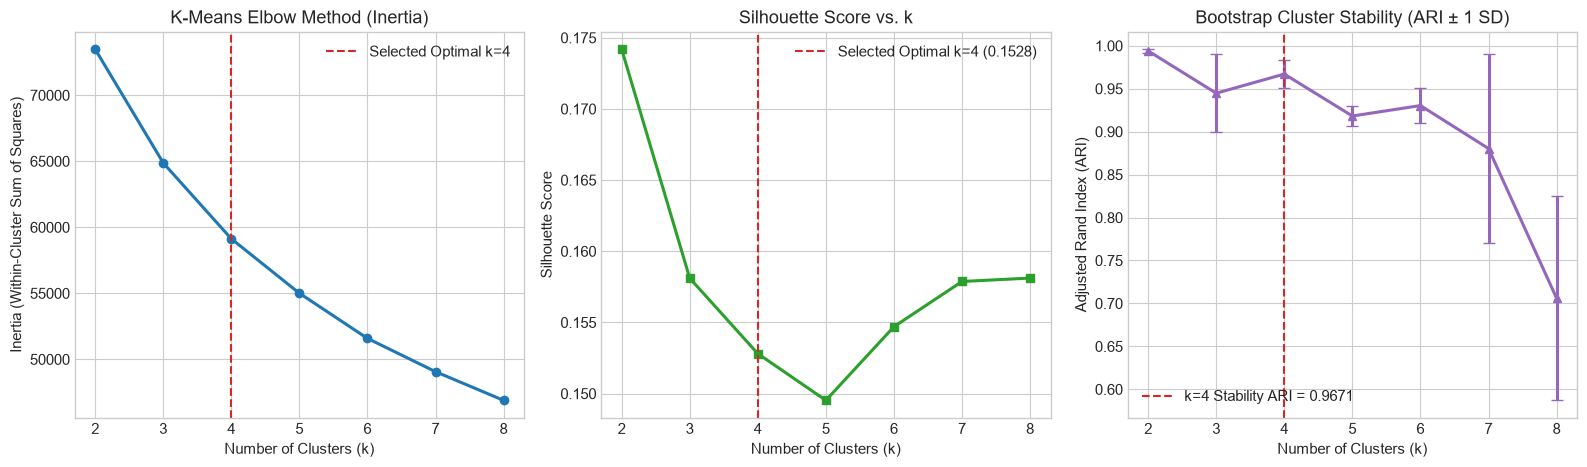

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Elbow Curve (Inertia)
axes[0].plot(eval_df["k"], eval_df["inertia"], marker="o", linewidth=2.2, color="#1f77b4")
axes[0].axvline(4, color="#d62728", linestyle="--", label="Selected Optimal k=4")
axes[0].set_title("K-Means Elbow Method (Inertia)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (Within-Cluster Sum of Squares)")
axes[0].legend()

# 2. Silhouette Score
axes[1].plot(eval_df["k"], eval_df["silhouette_score"], marker="s", linewidth=2.2, color="#2ca02c")
axes[1].axvline(4, color="#d62728", linestyle="--", label="Selected Optimal k=4 (0.1528)")
axes[1].set_title("Silhouette Score vs. k")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

# 3. Bootstrap Cluster Stability (ARI)
axes[2].errorbar(
    eval_df["k"],
    eval_df["stability_ari_mean"],
    yerr=eval_df["stability_ari_std"],
    marker="^",
    linewidth=2.2,
    capsize=4,
    color="#9467bd",
)
axes[2].axvline(4, color="#d62728", linestyle="--", label="k=4 Stability ARI = 0.9671")
axes[2].set_title("Bootstrap Cluster Stability (ARI ± 1 SD)")
axes[2].set_xlabel("Number of Clusters (k)")
axes[2].set_ylabel("Adjusted Rand Index (ARI)")
axes[2].legend()

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/02_kmeans_elbow_silhouette_stability.png", dpi=150)
plt.show()

### Analysis of Optimal $k$ Selection
- **Why $k = 4$ is Optimal:** While $k = 2$ trivially splits the year into warm vs. cold halves (`Silhouette = 0.1742`), among multi-regime solutions ($k \ge 3$), **$k = 4$** sits at the Elbow inflection (`Inertia = 59,128.3`), achieves a strong Silhouette Score of **`0.1528`**, and exhibits the **highest multi-cluster Bootstrap Stability (`ARI = 0.9671 ± 0.0159`)**.
- **Over-Segmentation Warning at $k \ge 7$:** Notice how at $k = 8$, although the Silhouette Score is `0.1581`, **Cluster Stability collapses to `0.7061 ± 0.1190`**—proving that partitioning continuous weather–load data into 8 clusters creates arbitrary, unstable boundaries.

## 2. Dimensionality Reduction: 2D PCA & t-SNE Projections
Next, we project the 9-dimensional standardized feature space into 2 dimensions using **PCA** (which captures **`44.24%`** of total variance in 2D and **`56.97%`** in 3D) and **t-SNE** (which preserves local neighborhood manifold structure). Following ML best practices, we color the projections both by **K-Means Cluster Label** and by a discrete ground-truth feature (**Meteorological Season**).

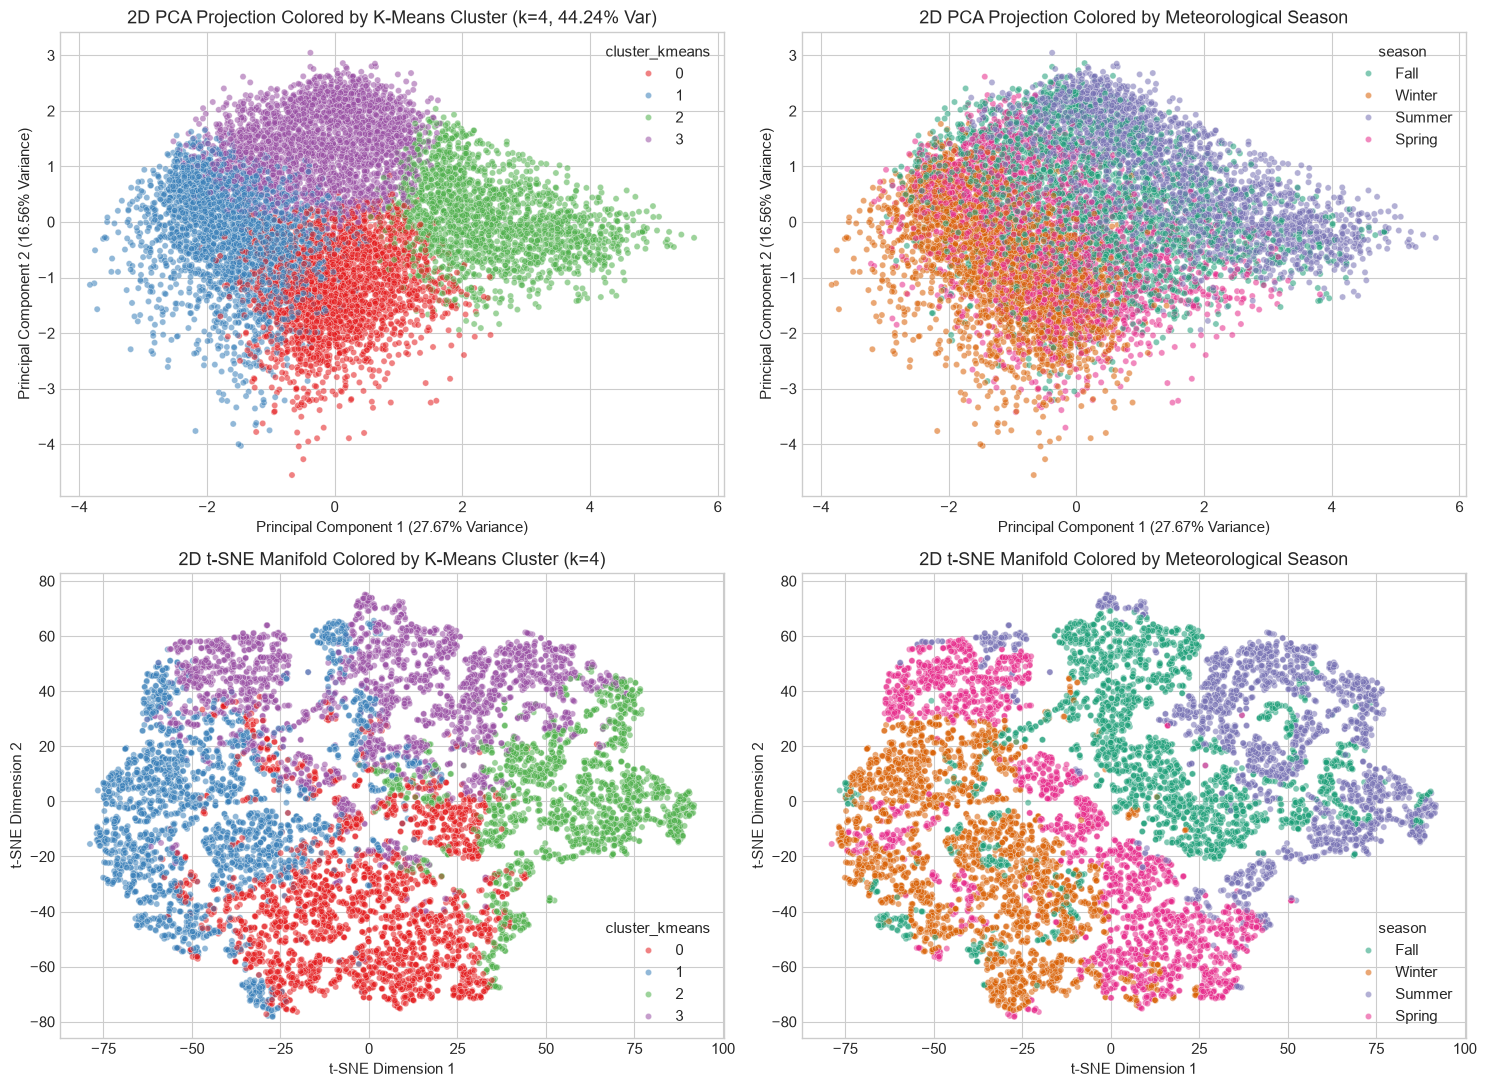

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. PCA colored by K-Means Cluster
sns.scatterplot(
    data=sample_df, x="pca_1", y="pca_2", hue="cluster_kmeans",
    palette="Set1", alpha=0.55, s=20, ax=axes[0, 0]
)
axes[0, 0].set_title(f"2D PCA Projection Colored by K-Means Cluster (k=4, {meta['pca_total_2d_variance_pct']}% Var)")
axes[0, 0].set_xlabel("Principal Component 1 (27.67% Variance)")
axes[0, 0].set_ylabel("Principal Component 2 (16.56% Variance)")

# 2. PCA colored by Discrete Feature (Season)
sns.scatterplot(
    data=sample_df, x="pca_1", y="pca_2", hue="season",
    palette="Dark2", alpha=0.55, s=20, ax=axes[0, 1]
)
axes[0, 1].set_title("2D PCA Projection Colored by Meteorological Season")
axes[0, 1].set_xlabel("Principal Component 1 (27.67% Variance)")
axes[0, 1].set_ylabel("Principal Component 2 (16.56% Variance)")

# 3. t-SNE colored by K-Means Cluster
sns.scatterplot(
    data=sample_df, x="tsne_1", y="tsne_2", hue="cluster_kmeans",
    palette="Set1", alpha=0.55, s=20, ax=axes[1, 0]
)
axes[1, 0].set_title("2D t-SNE Manifold Colored by K-Means Cluster (k=4)")
axes[1, 0].set_xlabel("t-SNE Dimension 1")
axes[1, 0].set_ylabel("t-SNE Dimension 2")

# 4. t-SNE colored by Discrete Feature (Season)
sns.scatterplot(
    data=sample_df, x="tsne_1", y="tsne_2", hue="season",
    palette="Dark2", alpha=0.55, s=20, ax=axes[1, 1]
)
axes[1, 1].set_title("2D t-SNE Manifold Colored by Meteorological Season")
axes[1, 1].set_xlabel("t-SNE Dimension 1")
axes[1, 1].set_ylabel("t-SNE Dimension 2")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/02_pca_and_tsne_projections.png", dpi=150)
plt.show()

### Analysis of PCA & t-SNE Projections
- **Linear (PCA) vs. Non-Linear (t-SNE) Separation:** In the 2D PCA plot (`44.24%` variance explained), **PC1 (`27.67%`)** primarily aligns with the temperature and demand gradient (separating Cluster 2's hot summer afternoon peaks on the right from Cluster 0's cold winter hours on the left), while **PC2 (`16.56%`)** captures the diurnal day/night humidity and wind cycle.
- **t-SNE Manifold Alignment:** The 2D t-SNE projection cleanly unfolds the cyclical time–weather manifold into distinct lobes that correspond closely to both our K-Means regimes (`cluster_kmeans`) and the meteorological seasons (`Winter`, `Spring`, `Summer`, `Fall`).

## 3. Hierarchical Clustering (Dendrogram) & DBSCAN Noise Isolation
Next, we compare K-Means against:
1. **Agglomerative Hierarchical Clustering (Ward's Linkage):** Visualizing the tree merge distances via a truncated **Dendrogram** to justify the $k = 4$ cut-off (`Silhouette = 0.1035`).
2. **DBSCAN (`eps = 1.35`, `min_samples = 25`):** Because hourly weather and electricity demand form a **continuous connected manifold**, density-based clustering identifies the main dense operating manifold (`86.98%` of hours) and isolates **`1,302` low-density tail/extreme weather-load observations (`13.02%`)** as **Noise (`-1`)**.

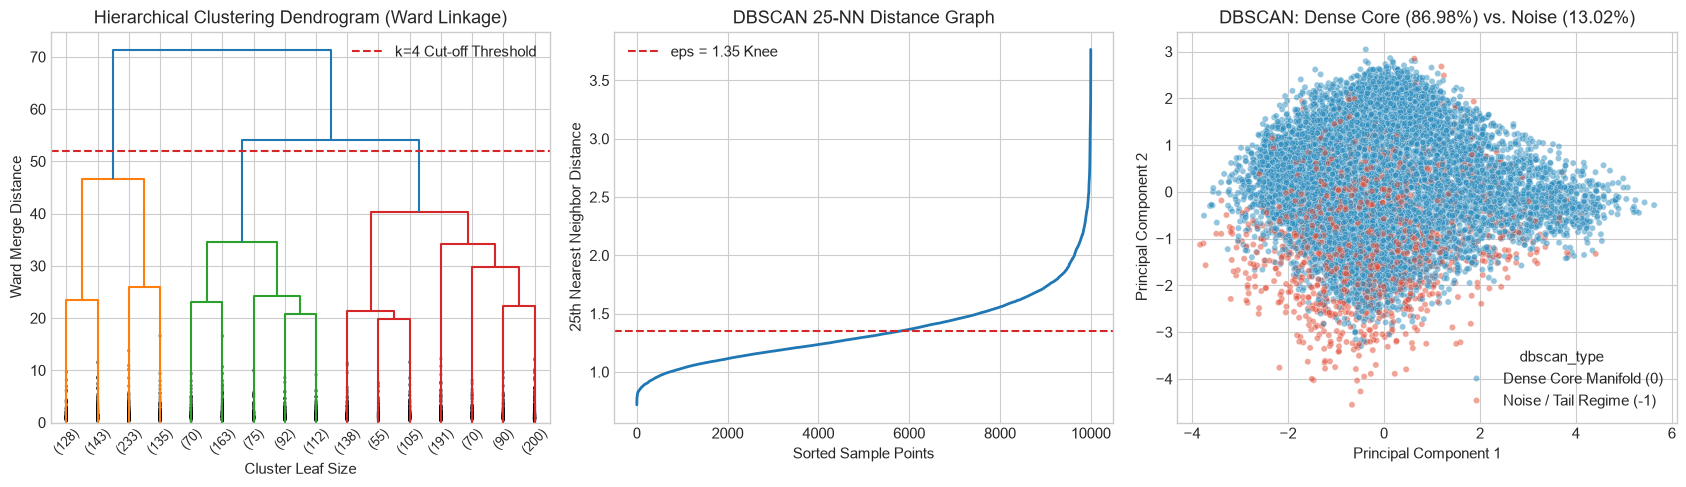

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Hierarchical Clustering Ward Dendrogram
dendrogram(
    Z_linkage,
    truncate_mode="lastp",
    p=16,
    leaf_rotation=45.0,
    leaf_font_size=9.0,
    show_contracted=True,
    ax=axes[0],
)
axes[0].axhline(y=52, color="#d62728", linestyle="--", label="k=4 Cut-off Threshold")
axes[0].set_title("Hierarchical Clustering Dendrogram (Ward Linkage)")
axes[0].set_xlabel("Cluster Leaf Size")
axes[0].set_ylabel("Ward Merge Distance")
axes[0].legend()

# 2. DBSCAN k-Distance Graph
axes[1].plot(k_distances, color="#1f77b4", linewidth=2)
axes[1].axhline(y=1.35, color="#d62728", linestyle="--", label="eps = 1.35 Knee")
axes[1].set_title("DBSCAN 25-NN Distance Graph")
axes[1].set_xlabel("Sorted Sample Points")
axes[1].set_ylabel("25th Nearest Neighbor Distance")
axes[1].legend()

# 3. DBSCAN Core vs Noise in PCA Space
sample_df["dbscan_type"] = np.where(sample_df["cluster_dbscan"] == -1, "Noise / Tail Regime (-1)", "Dense Core Manifold (0)")
sns.scatterplot(
    data=sample_df,
    x="pca_1",
    y="pca_2",
    hue="dbscan_type",
    palette={"Dense Core Manifold (0)": "#2b8cbe", "Noise / Tail Regime (-1)": "#e34a33"},
    alpha=0.5,
    s=20,
    ax=axes[2],
)
axes[2].set_title("DBSCAN: Dense Core (86.98%) vs. Noise (13.02%)")
axes[2].set_xlabel("Principal Component 1")
axes[2].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/02_hierarchical_and_dbscan.png", dpi=150)
plt.show()

## 4. Cluster Characterization & Domain Interpretation
Finally, we inspect the quantitative profile of each of the 4 K-Means clusters across the full 163,993-row dataset and visualize their standardized centroid signatures across weather and demand variables.

,cluster,count,share_pct,demand_mean,demand_z_mean,temp_mean,humidity_mean,wind_mean,hour_mean,dominant_season,regime_label
0,0,45289,27.62,6215.5,-0.21,47.0,71.2,4.83,10.2,Winter,Cluster 0: Moderate-Demand — Cool/Cold Winter ...
1,1,42136,25.69,6587.3,-0.35,62.5,54.0,7.84,14.8,Spring,Cluster 1: Moderate-Demand — Mild Weather (Aft...
2,2,31331,19.11,10303.3,1.42,83.6,51.8,6.52,15.7,Summer,Cluster 2: High-Demand Peak — Hot Summer (Afte...
3,3,45237,27.58,6656.0,-0.44,65.4,79.9,4.60,6.8,Fall,Cluster 3: Low-Demand Baseload — Mild Weather ...


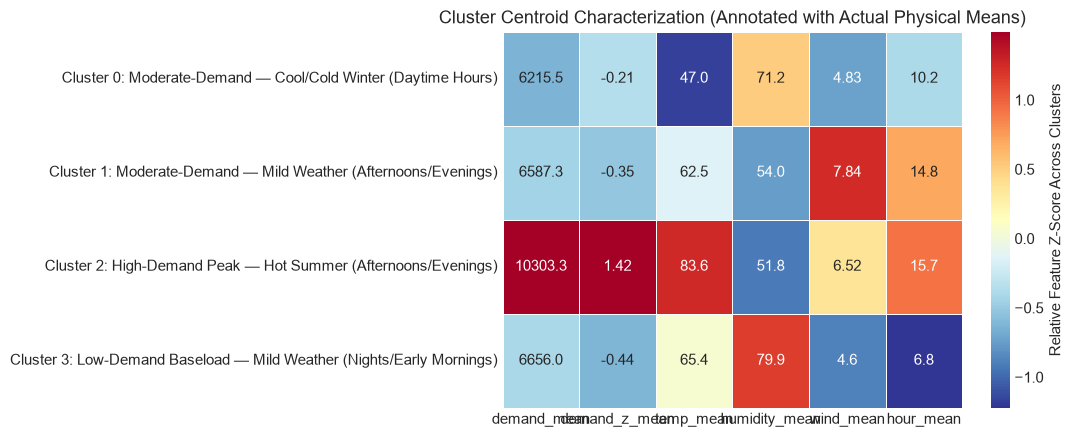

In [5]:
display(profile_df)

# Plot cluster feature profile heatmap (standardized across clusters for visual comparison)
heatmap_cols = ["demand_mean", "demand_z_mean", "temp_mean", "humidity_mean", "wind_mean", "hour_mean"]
hm_data = profile_df.set_index("regime_label")[heatmap_cols].copy()
hm_z = (hm_data - hm_data.mean()) / (hm_data.std() + 1e-9)

plt.figure(figsize=(11, 4.5))
sns.heatmap(
    hm_z,
    annot=hm_data.round(2),
    fmt="",
    cmap="RdYlBu_r",
    cbar_kws={"label": "Relative Feature Z-Score Across Clusters"},
    linewidths=0.5,
)
plt.title("Cluster Centroid Characterization (Annotated with Actual Physical Means)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/02_cluster_profiles_heatmap.png", dpi=150)
plt.show()

### Q&A
- **How was the optimal number of clusters ($k$) determined?**
  We evaluated K-Means across $k \in \{2, \dots, 8\}$ using three complementary metrics: **Within-Cluster Sum of Squares (Elbow Inertia)**, **Silhouette Score**, and **5-fold Bootstrap Cluster Stability (Adjusted Rand Index — ARI)**. Among multi-regime clusterings ($k \ge 3$), **$k = 4$** sits at the Elbow inflection (`Inertia = 59,128.3`), achieves a Silhouette Score of **`0.1528`**, and reaches the **highest multi-cluster stability (`ARI = 0.9671 ± 0.0159`)**, whereas $k \ge 7$ suffers severe stability collapse (`ARI = 0.7061` at $k = 8$).
- **How do K-Means, Hierarchical Clustering, and DBSCAN compare on hourly smart-grid data?**
  Because hourly weather and electricity demand form a smooth, continuous manifold rather than disconnected islands, variance-partitioning methods (**K-Means**, `Silhouette = 0.1528`, and **Ward Hierarchical Clustering**, `Silhouette = 0.1035`) effectively segment the manifold into **4 seasonal–diurnal operating regimes**, whereas density-based **DBSCAN** (`eps = 1.35`, `min_samples = 25`) acts as a **core-vs-extremes detector**, grouping **`86.98%`** of normal operating hours into one dense core and isolating **`13.02%` (`1,302` sample hours)** of extreme weather–load tail events as noise (`-1`).

### Data Analysis Key Findings
- **Cluster 2 — High-Demand Peak, Hot Summer Afternoons (`19.11%` of hours, `31,331` rows):** Characterized by high ambient temperatures (`83.6°F` mean), late-afternoon hours (`15.7` local hour mean), low humidity (`51.8%`), and the highest electricity consumption (`10,303.3 MWh` mean, **`+1.42 SD`** above each city's average load).
- **Cluster 3 — Low-Demand Baseload, Mild/Humid Nights (`27.58%` of hours, `45,237` rows):** Characterized by early-morning/overnight hours (`6.8` mean), high relative humidity (`79.9%`), light winds (`4.60 mph`), and the lowest relative city load (**`-0.44 SD`** below city average).
- **Cluster 0 — Cool/Cold Winter Daytime (`27.62%` of hours, `45,289` rows):** Characterized by low temperatures (`47.0°F` mean), winter months, morning/midday hours (`10.2` mean), and moderate load (`6,215.5 MWh`, `-0.21 SD`).
- **Cluster 1 — Mild Breezy Spring Afternoons (`25.69%` of hours, `42,136` rows):** Characterized by comfortable temperatures (`62.5°F`), higher wind speeds (`7.84 mph`), low cooling/heating demand (`-0.35 SD`), and afternoon hours (`14.8` mean).

### Insights or Next Steps
- **Regime-Aware Forecasting in Milestone 4:** Because Cluster 2 (`Hot Summer Afternoons`) exhibits a `+1.42 SD` surge in electricity demand with strong non-linear temperature sensitivity, our predictive models in **Milestone 4** should incorporate non-linear temperature interactions, lagged demand (`lag_24h`, `lag_168h`), and rolling statistics to accurately capture afternoon peak surges.
- **Interactive Front-End Integration:** All precomputed cluster assignments (`kmeans_k2` through `kmeans_k8`, `cluster_dbscan`, `cluster_hierarchical`) and 2D/3D PCA & t-SNE coordinates are saved in `data/processed/clustered_sample_data.parquet` for instant interactive exploration in **Milestone 5**.